# Five-Model Coffee Cooling Comparison Demo

This notebook demonstrates a comparative analysis of five models for coffee cooling trajectories based on published experimental data. It reproduces core results from the associated research.

The models evaluated are:
1. **B0 (Newton)**: Baseline single-exponential decay.
2. **B1 (Piecewise)**: Two-exponential regime switch.
3. **C1 (Coupled ODE)**: Mass-energy coupled system with evaporation.
4. **C2 (Bayesian Change-point)**: MAP estimate of a regime switch.
5. **C3 (Flux-crossover)**: Evaporation suppression mechanism.

We compare them based on BIC and predictive accuracy for the drinkable temperature (50°C).

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q numpy==2.0.0 pandas scipy matplotlib loguru
else:
    # Locally, we assume the environment is already prepared or we don't install
    pass

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, curve_fit
from loguru import logger
from typing import Any, Dict, List, Optional

# Colour scheme for the project
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

In [3]:
import http.client
import json
import urllib.request
from pathlib import Path

GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-06eccf-crema-breakdown-regime-switch-predicts/main/round-1/experiment-1/demo/mini_demo_data.json"

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


In [4]:
# Config
MIN_ITERATIONS = 1
SPLIT_RATIO = 0.8

# Constants from original script
LATENT_HEAT_VAP_J_PER_KG: float = 2260e3
SPECIFIC_HEAT_WATER_J_PER_KG_K: float = 4186.0
DRINKABLE_TEMP_C: float = 50.0
TAU_SWEEP_MINUTES: List[float] = [3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
DEFAULT_T_ENV_C: float = 21.0


### Data visualization

findfont: Failed to find font weight normal for CMU Serif, now using 500.


findfont: Failed to find font weight normal for CMU Serif, now using 500.


Dataset: kurzweg_1988


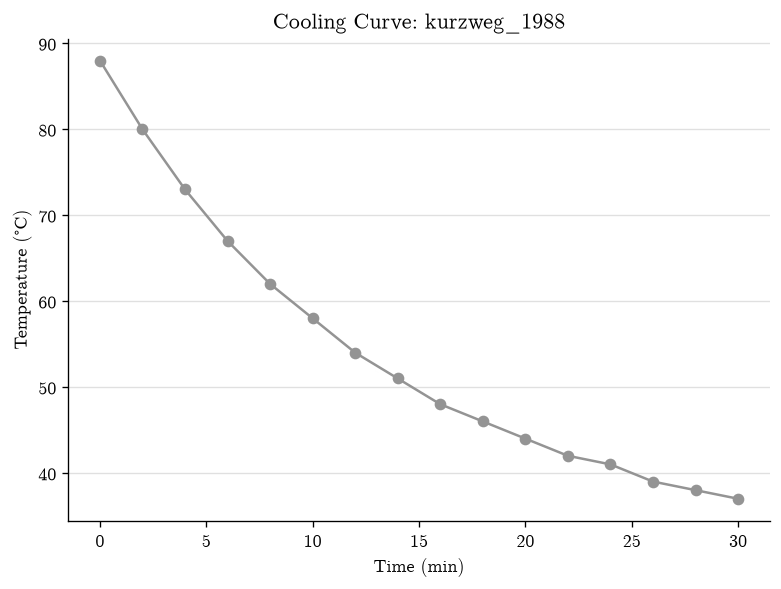

In [5]:
for entry in data:
    print(f"Dataset: {entry['name']}")
    plt.figure()
    plt.plot(entry['t_min'], entry['T_C'], 'o-', label='Observed', color=COLOURS['baseline'])
    plt.xlabel('Time (min)')
    plt.ylabel('Temperature (°C)')
    plt.title(f'Cooling Curve: {entry["name"]}')
    plt.show()

### Model definitions (copied from original method.py)

In [6]:
def newton_model(t_s: np.ndarray, k: float, T0: float, Te: float) -> np.ndarray:
    """Newton single-exponential cooling model."""
    return Te + (T0 - Te) * np.exp(-k * t_s)


def piecewise_two_exponential(
    t_s: np.ndarray,
    k1: float,
    T0_1: float,
    Te1: float,
    t_switch_s: float,
    k2: float,
    T0_2: float,
    Te2: float,
) -> np.ndarray:
    """
    Two exponential regimes joined at t_switch.
    
    For t <= t_switch: T = Te1 + (T0_1 - Te1) * exp(-k1 * t)
    For t > t_switch: T = Te2 + (T0_2 - Te2) * exp(-k2 * (t - t_switch))
    """
    mask = t_s <= t_switch_s
    result = np.empty_like(t_s, dtype=float)
    result[mask] = Te1 + (T0_1 - Te1) * np.exp(-k1 * t_s[mask])
    t_rel = t_s[~mask] - t_switch_s
    result[~mask] = Te2 + (T0_2 - Te2) * np.exp(-k2 * t_rel)
    return result


def coupled_TM_ode(
    t_s: float,
    y: np.ndarray,
    Te: float,
    h_A_over_m: float,
    h_covered: float,
    L: float,
    c_p: float,
    h_vap_coeff: float,
) -> List[float]:
    """
    Coupled temperature-mass ODE with Hertz-Knudsen-like evaporation.
    
    y[0] = T (temperature in °C)
    y[1] = m (mass in kg)
    
    dT/dt = -(q_conv + q_evap) / (m * c_p)
    dm/dt = -q_evap / L
    """
    T, m = y
    
    # Evaporative flux proportional to saturation vapor pressure at T (Antoine eq approx)
    # Simplified Antoine: P_sat = exp(23.196 - 3816 / (T + 228))
    P_sat = np.exp(23.196 - 3816.0 / (T + 228.0))
    
    # Convective flux (Newton cooling)
    q_conv = h_covered * (T - Te)
    
    # Evaporative contribution (reduced by remaining crema coverage fraction)
    # tau = 300 s (5 min)
    crema_coverage = np.exp(-t_s / 300.0)
    q_evap = h_vap_coeff * crema_coverage * P_sat
    
    dTdt = -(q_conv + q_evap) / (m * c_p)
    dmdt = -q_evap / L
    
    return [dTdt, dmdt]


def flux_crossover_model(
    t_s: np.ndarray,
    k_conv: float,
    T0: float,
    Te: float,
    tau_min: float,
    beta: float,
    max_step: float = 5.0,
) -> np.ndarray:
    """
    Newton cooling with evaporation suppression factor exp(-t/tau).
    
    Effective k varies with time: k_eff(t) = k_conv * (1 + beta * exp(-t/tau)).
    Solve dT/dt = -k_eff(t) * (T - Te) via ODE integration.
    
    tau in minutes, converted to seconds internally.
    """
    tau_sec = tau_min * 60.0
    
    def rhs(t_val: float, T_val: float) -> float:
        return -k_conv * (1.0 + beta * np.exp(-t_val / tau_sec)) * (T_val - Te)
    
    sol = solve_ivp(
        rhs,
        [0.0, float(np.max(t_s))],
        [T0],
        t_eval=t_s,
        max_step=max_step,
        rtol=1e-9,
        atol=1e-9,
    )
    
    if not sol.success:
        raise RuntimeError(f"solve_ivp failed: {sol.message}")
    
    return sol.y[0]

### Fitting functions

In [7]:
def fit_newton(fit_data: Dict[str, Any]) -> Dict[str, Any]:
    """
    B0: Newton single-exponential, least squares on transformed variable.
    
    Parameters:
    - k: cooling rate constant (1/s)
    - T0: initial temperature (°C)
    """
    t_s = fit_data["t_min"] * 60.0
    T = fit_data["T_C"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    # Linear regression: log((T - Te) / (T0 - Te)) = -k * t_s
    log_ratio = np.log((T - Te) / (T0 - Te))
    
    # Handle potential negative values in log argument
    mask = (T - Te) > 0
    if np.sum(mask) < 2:
        # Fallback: use all points, clip to small positive
        log_ratio = np.log(np.maximum((T - Te) / (T0 - Te), 1e-6))
    
    coeffs = np.polyfit(t_s, log_ratio, 1)
    k = -coeffs[0]
    
    rss = np.sum((newton_model(t_s, k, T0, Te) - T) ** 2)
    n = len(T)
    bic = n * np.log(rss / n) + 2 * 2  # 2 parameters: k, T0
    
    return {
        "model": "B0_newton",
        "k": k,
        "T0": T0,
        "rss": rss,
        "bic": bic,
        "params_count": 2,
    }

In [8]:
def fit_piecewise(fit_data: Dict[str, Any]) -> Dict[str, Any]:
    """
    B1: Profile likelihood over switching time t_switch in [2, 20] min.
    
    Parameters:
    - k1, T0_1: first regime
    - k2, T0_2: second regime
    - t_switch: switching time (seconds)
    """
    t_s = fit_data["t_min"] * 60.0
    T = fit_data["T_C"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    best_bic = np.inf
    best_params: Optional[Dict[str, Any]] = None
    
    # t_switch candidates from 2 to 20 min
    t_switch_candidates = np.linspace(120, 1200, 30)
    
    for t_sw in t_switch_candidates:
        mask = t_s <= t_sw
        t1, T1 = t_s[mask], T[mask]
        t2, T2 = t_s[~mask], T[~mask]
        t2_rel = t2 - t_sw
        
        if len(t1) < 2 or len(t2) < 2:
            continue
        
        try:
            # Fit first regime: T = Te + (T0_1 - Te) * exp(-k1 * t)
            p1, _ = curve_fit(
                lambda tt, kk, T0_1: Te + (T0_1 - Te) * np.exp(-kk * tt),
                t1,
                T1,
                p0=[0.01, T0],
                maxfev=10000,
            )
            
            # Fit second regime: T = Te + (T0_2 - Te) * exp(-k2 * (t - t_sw))
            p2, _ = curve_fit(
                lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
                t2_rel,
                T2,
                p0=[0.02, T[~mask].mean()],
                maxfev=10000,
            )
            
            # Compute RSS
            pred1 = Te + (p1[1] - Te) * np.exp(-p1[0] * t1)
            pred2 = Te + (p2[1] - Te) * np.exp(-p2[0] * t2_rel)
            pred = np.concatenate([pred1, pred2])
            
            rss = np.sum((pred - T) ** 2)
            n = len(T)
            bic = n * np.log(rss / n) + 2 * 5  # 5 parameters: k1, T0_1, k2, T0_2, t_switch
            
            if bic < best_bic:
                best_bic = bic
                best_params = {
                    "k1": p1[0],
                    "T0_1": p1[1],
                    "k2": p2[0],
                    "T0_2": p2[1],
                    "t_switch_s": t_sw,
                    "rss": rss,
                    "bic": bic,
                }
        except (RuntimeError, ValueError):
            continue
    
    if best_params is None:
        # Fallback: return worst-case
        return {
            "model": "B1_piecewise",
            "k1": np.nan,
            "T0_1": np.nan,
            "k2": np.nan,
            "T0_2": np.nan,
            "t_switch_s": np.nan,
            "rss": np.nan,
            "bic": np.nan,
            "params_count": 5,
        }
    
    return {"model": "B1_piecewise", "params_count": 5, **best_params}

In [9]:
def fit_coupled_ode(fit_data: Dict[str, Any]) -> Dict[str, Any]:
    """
    C1: Fit coupled TM-ODE via Nelder-Mead on RSS.
    
    Parameters:
    - h_A_over_m: surface area to mass ratio
    - h_c: convective heat transfer coefficient
    - L: latent heat of vaporization (fixed at physical value)
    - c_p: specific heat (fixed at physical value)
    - h_vap: vaporization coefficient
    """
    t_s = fit_data["t_min"] * 60.0
    T = fit_data["T_C"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    def objective(params: np.ndarray) -> float:
        h_A_over_m, h_c, h_vap = params
        if any(p <= 0 for p in params):
            return 1e10
        
        sol = solve_ivp(
            lambda tt, yy: coupled_TM_ode(tt, yy, Te, h_A_over_m, h_c, LATENT_HEAT_VAP_J_PER_KG, SPECIFIC_HEAT_WATER_J_PER_KG_K, h_vap),
            [0.0, t_s[-1]],
            [T0, 0.25],
            t_eval=t_s,
            max_step=5.0,
            rtol=1e-6,
            atol=1e-6,
        )
        
        if not sol.success:
            return 1e10
        
        pred = sol.y[0]
        rss = np.sum((pred - T) ** 2)
        return rss
    
    # Initial guess
    x0 = np.array([10.0, 5.0, 0.01])
    
    res = minimize(
        objective,
        x0,
        method="Nelder-Mead",
        options={"maxiter": 1000, "xatol": 1e-6, "fatol": 1e-6},
    )
    
    rss = res.fun
    n = len(T)
    bic = n * np.log(rss / n) + 2 * 3  # 3 free parameters
    
    return {
        "model": "C1_coupled_ode",
        "params": res.x.tolist(),
        "rss": rss,
        "bic": bic,
        "params_count": 3,
    }

In [10]:
def fit_bayesian_changepoint(fit_data: Dict[str, Any]) -> Dict[str, Any]:
    """
    C2: Simplified Bayesian change-point detection via MAP estimation.
    
    Instead of full MCMC, we use a deterministic MAP estimate by profiling
    over the change-point location. This avoids requiring pymc/pomegranate.
    
    The model assumes:
    - Before t_cp: T follows Newton law with rate k1
    - After t_cp: T follows Newton law with rate k2
    - t_cp is the change-point location
    
    We maximize the posterior (equivalently, minimize BIC-like criterion)
    over t_cp.
    """
    t_s = fit_data["t_min"] * 60.0
    T = fit_data["T_C"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    best_bic = np.inf
    best_cp: Optional[float] = None
    best_k1 = best_k2 = np.nan
    
    # Candidate change points: 1 to 90% of total time
    t_max = t_s[-1]
    cp_candidates = np.linspace(t_max * 0.1, t_max * 0.9, 50)
    
    for cp in cp_candidates:
        mask1 = t_s <= cp
        mask2 = t_s > cp
        
        if np.sum(mask1) < 2 or np.sum(mask2) < 2:
            continue
        
        t1, T1 = t_s[mask1], T[mask1]
        t2, T2 = t_s[mask2], T[mask2]
        
        try:
            # Fit first regime
            log_ratio1 = np.log(np.maximum((T1 - Te) / (T0 - Te), 1e-6))
            coeffs1 = np.polyfit(t1, log_ratio1, 1)
            k1 = -coeffs1[0]
            
            # Fit second regime (relative time)
            T2_fit = T2
            T_ref = T1[-1]  # Temperature at change point
            t2_rel = t2 - cp
            log_ratio2 = np.log(np.maximum((T2_fit - Te) / (T_ref - Te), 1e-6))
            coeffs2 = np.polyfit(t2_rel, log_ratio2, 1)
            k2 = -coeffs2[0]
            
            # Compute RSS
            pred1 = Te + (T0 - Te) * np.exp(-k1 * t1)
            pred2 = Te + (T_ref - Te) * np.exp(-k2 * t2_rel)
            pred = np.concatenate([pred1, pred2])
            
            rss = np.sum((pred - T) ** 2)
            n = len(T)
            bic = n * np.log(rss / n) + 2 * 3  # 3 parameters: k1, k2, t_cp
            
            if bic < best_bic:
                best_bic = bic
                best_cp = cp
                best_k1 = k1
                best_k2 = k2
        except (RuntimeError, ValueError):
            continue
    
    if best_cp is None:
        return {
            "model": "C2_bayesian_changepoint",
            "k1": np.nan,
            "k2": np.nan,
            "t_cp_s": np.nan,
            "rss": np.nan,
            "bic": np.nan,
            "params_count": 3,
        }
    
    # Recompute RSS for the best change point
    mask1 = t_s <= best_cp
    mask2 = t_s > best_cp
    t1, T1 = t_s[mask1], T[mask1]
    t2, T2 = t_s[mask2], T[mask2]
    T_ref = T1[-1]
    t2_rel = t2 - best_cp
    pred1 = Te + (T0 - Te) * np.exp(-best_k1 * t1)
    pred2 = Te + (T_ref - Te) * np.exp(-best_k2 * t2_rel)
    pred = np.concatenate([pred1, pred2])
    rss = float(np.sum((pred - T) ** 2))
    
    return {
        "model": "C2_bayesian_changepoint",
        "k1": best_k1,
        "k2": best_k2,
        "t_cp_s": best_cp,
        "rss": rss,
        "bic": best_bic,
        "params_count": 3,
    }

In [11]:
def fit_flux_crossover(fit_data: Dict[str, Any], tau: float) -> Dict[str, Any]:
    """
    C3: For a fixed tau (minutes), fit k_conv and beta via Nelder-Mead.
    
    Parameters:
    - k_conv: convective cooling rate
    - beta: evaporation suppression strength
    - tau: crema half-life (minutes, fixed)
    """
    t_s = fit_data["t_min"] * 60.0
    T = fit_data["T_C"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    def objective(params: np.ndarray) -> float:
        k_conv, beta = params
        if k_conv <= 1e-6 or beta < 0:
            return 1e10
        
        try:
            pred = flux_crossover_model(t_s, k_conv, T0, Te, tau, beta)
            rss = np.sum((pred - T) ** 2)
            return rss
        except Exception:
            return 1e10
    
    x0 = np.array([0.005, 2.0])
    
    res = minimize(
        objective,
        x0,
        method="Nelder-Mead",
        options={"maxiter": 1000, "xatol": 1e-8, "fatol": 1e-8},
    )
    
    rss = res.fun
    n = len(T)
    bic = n * np.log(rss / n) + 2 * 3  # 3 parameters: k_conv, beta, tau (fixed)
    
    return {
        "model": f"C3_flux_crossover_tau{tau}",
        "k_conv": res.x[0],
        "beta": res.x[1],
        "tau_min": tau,
        "rss": rss,
        "bic": bic,
        "params_count": 3,
    }

### Prediction helpers

In [12]:
def predict_t_drinkable_newton(model_result: Dict[str, Any], fit_data: Dict[str, Any]) -> float:
    """Find first time when Newton model crosses DRINKABLE_TEMP_C."""
    k = model_result["k"]
    T0 = model_result["T0"]
    Te = fit_data["T_env_C"]
    
    if T0 <= Te:
        return np.nan
    
    # Solve Te + (T0 - Te) * exp(-k * t) = 50
    # exp(-k * t) = (50 - Te) / (T0 - Te)
    ratio = (DRINKABLE_TEMP_C - Te) / (T0 - Te)
    
    if ratio <= 0 or ratio >= 1:
        # Never crosses or already below
        return np.nan
    
    t_cross_s = -np.log(ratio) / k
    return t_cross_s / 60.0  # Return in minutes

In [13]:
def predict_t_drinkable_piecewise(model_result: Dict[str, Any], fit_data: Dict[str, Any]) -> float:
    """Find first time when piecewise model crosses DRINKABLE_TEMP_C."""
    k1 = model_result["k1"]
    T0_1 = model_result["T0_1"]
    k2 = model_result["k2"]
    T0_2 = model_result["T0_2"]
    t_sw = model_result["t_switch_s"]
    Te = fit_data["T_env_C"]
    
    if np.isnan(k1) or np.isnan(k2):
        return np.nan
    
    # Check first regime
    if T0_1 > Te:
        ratio1 = (DRINKABLE_TEMP_C - Te) / (T0_1 - Te)
        if 0 < ratio1 < 1:
            t1_cross = -np.log(ratio1) / k1
            if t1_cross <= t_sw:
                return t1_cross / 60.0
    
    # Second regime
    if T0_2 > Te:
        ratio2 = (DRINKABLE_TEMP_C - Te) / (T0_2 - Te)
        if 0 < ratio2 < 1:
            t2_cross = t_sw - np.log(ratio2) / k2
            return t2_cross / 60.0
    
    return np.nan

In [14]:
def predict_t_drinkable_c1(model_result: Dict[str, Any], fit_data: Dict[str, Any]) -> float:
    """Find first time when coupled ODE model crosses DRINKABLE_TEMP_C via numerical search."""
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    t_max = np.max(fit_data["t_min"]) * 60.0 * 1.5  # Extend beyond data range
    
    params = model_result.get("params", [])
    if len(params) < 3:
        return np.nan
    
    h_A_over_m, h_c, h_vap = params[:3]
    
    t_grid = np.linspace(0, t_max, 600)
    
    try:
        sol = solve_ivp(
            lambda tt, yy: coupled_TM_ode(tt, yy, Te, h_A_over_m, h_c, LATENT_HEAT_VAP_J_PER_KG, SPECIFIC_HEAT_WATER_J_PER_KG_K, h_vap),
            [0.0, t_max],
            [T0, 0.25],
            t_eval=t_grid,
            max_step=5.0,
            rtol=1e-6,
            atol=1e-6,
        )
        if not sol.success:
            return np.nan
        pred = sol.y[0]
        crossings = np.where(pred <= DRINKABLE_TEMP_C)[0]
        if len(crossings) == 0:
            return np.nan
        return float(t_grid[crossings[0]] / 60.0)
    except Exception:
        return np.nan

In [15]:
def predict_t_drinkable_c2(model_result: Dict[str, Any], fit_data: Dict[str, Any]) -> float:
    """Find first time when Bayesian change-point model crosses DRINKABLE_TEMP_C."""
    k1 = model_result["k1"]
    k2 = model_result["k2"]
    t_cp = model_result["t_cp_s"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    if np.isnan(k1) or np.isnan(k2):
        return np.nan
    
    # First regime
    if T0 > Te:
        ratio1 = (DRINKABLE_TEMP_C - Te) / (T0 - Te)
        if 0 < ratio1 < 1:
            t1_cross = -np.log(ratio1) / k1
            if t1_cross <= t_cp:
                return t1_cross / 60.0
    
    # Second regime (starting from temperature at change point)
    T_at_cp = Te + (T0 - Te) * np.exp(-k1 * t_cp)
    if T_at_cp > Te:
        ratio2 = (DRINKABLE_TEMP_C - Te) / (T_at_cp - Te)
        if 0 < ratio2 < 1:
            t2_cross = t_cp - np.log(ratio2) / k2
            return t2_cross / 60.0
    
    return np.nan

In [16]:
def predict_t_drinkable_c3(model_result: Dict[str, Any], fit_data: Dict[str, Any]) -> float:
    """Find first time when flux-crossover model crosses DRINKABLE_TEMP_C."""
    k_conv = model_result["k_conv"]
    beta = model_result["beta"]
    tau = model_result["tau_min"]
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    # Numerical search through fitted curve
    t_max = np.max(fit_data["t_min"]) * 60.0 * 1.5  # Extend beyond data range
    t_grid = np.linspace(0, t_max, 600)
    
    try:
        pred = flux_crossover_model(t_grid, k_conv, T0, Te, tau, beta)
        crossings = np.where(pred <= DRINKABLE_TEMP_C)[0]
        if len(crossings) == 0:
            return np.nan
        return t_grid[crossings[0]] / 60.0
    except Exception:
        return np.nan

### OOS evaluation

In [17]:
def compute_oos_rmse(model_result: Dict[str, Any], fit_data: Dict[str, Any], hold_data: Dict[str, Any]) -> float:
    """Compute out-of-sample RMSE for a given model."""
    T_hold = hold_data["T_C"]
    t_hold_s = hold_data["t_min"] * 60.0
    Te = fit_data["T_env_C"]
    T0 = fit_data["T0_C"]
    
    if model_result["model"] == "B0_newton":
        pred = newton_model(t_hold_s, model_result["k"], T0, Te)
    elif model_result["model"] == "B1_piecewise":
        pred = piecewise_two_exponential(
            t_hold_s,
            model_result["k1"],
            model_result["T0_1"],
            Te,
            model_result["t_switch_s"],
            model_result["k2"],
            model_result["T0_2"],
            Te,
        )
    elif model_result["model"].startswith("C1"):
        h_A_over_m, h_c, h_vap = model_result["params"]
        sol = solve_ivp(
            lambda tt, yy: coupled_TM_ode(tt, yy, Te, h_A_over_m, h_c, LATENT_HEAT_VAP_J_PER_KG, SPECIFIC_HEAT_WATER_J_PER_KG_K, h_vap),
            [0.0, np.max(t_hold_s)],
            [T0, 0.25],
            t_eval=t_hold_s,
            max_step=5.0,
        )
        pred = sol.y[0]
    elif model_result["model"].startswith("C2"):
        k1 = model_result["k1"]
        k2 = model_result["k2"]
        t_cp = model_result["t_cp_s"]
        
        mask1 = t_hold_s <= t_cp
        pred = np.empty_like(t_hold_s)
        
        if np.any(mask1):
            pred[mask1] = Te + (T0 - Te) * np.exp(-k1 * t_hold_s[mask1])
        
        if np.any(~mask1):
            T_at_cp = Te + (T0 - Te) * np.exp(-k1 * t_cp)
            t_rel = t_hold_s[~mask1] - t_cp
            pred[~mask1] = Te + (T_at_cp - Te) * np.exp(-k2 * t_rel)
    elif model_result["model"].startswith("C3"):
        pred = flux_crossover_model(t_hold_s, model_result["k_conv"], T0, Te, model_result["tau_min"], model_result["beta"])
    else:
        return np.nan
    
    if np.any(np.isnan(pred)):
        return np.nan
    
    rmse = np.sqrt(np.sum((pred - T_hold) ** 2) / len(T_hold))
    return float(rmse)

### Process single dataset

In [18]:
def process_dataset(dataset_dict: Dict[str, Any], split_ratio: float = 0.80) -> Dict[str, Any]:
    """Fit all models to one dataset with a given split ratio, return results block."""
    name = dataset_dict["name"]
    # Ensure numpy arrays
    t_all = np.array(dataset_dict["t_min"])
    T_all = np.array(dataset_dict["T_C"])
    logger.info(f"Processing dataset: {name} (split={split_ratio:.0%})")
    
    # Split: first `split_ratio` for fitting, rest for holdout evaluation
    
    split_idx = int(len(t_all) * split_ratio)
    
    # Ensure minimum 3 points in holdout
    split_idx = max(3, min(split_idx, len(t_all) - 3))
    
    t_fit = t_all[:split_idx]
    T_fit = T_all[:split_idx]
    t_hold = t_all[split_idx:]
    T_hold = T_all[split_idx:]
    
    fit_data = {
        "t_min": t_fit,
        "T_C": T_fit,
        "T_env_C": dataset_dict.get("T_env_C", DEFAULT_T_ENV_C),
        "T0_C": dataset_dict.get("T0_C", T_fit[0]),
    }
    hold_data = {
        "t_min": t_hold,
        "T_C": T_hold,
        "T_env_C": dataset_dict.get("T_env_C", DEFAULT_T_ENV_C),
    }
    
    results: Dict[str, Any] = {
        "dataset": name,
        "source": dataset_dict.get("source", "unknown"),
        "n_points": int(len(T_all)),
        "split_size_fit": int(split_idx),
        "split_size_hold": int(len(t_hold)),
    }
    
    # B0: Newton
    logger.info(f"  Fitting B0 (Newton) on {name}")
    b0 = fit_newton(fit_data)
    b0["oos_rmse"] = compute_oos_rmse(b0, fit_data, hold_data)
    b0["predicted_t_drinkable_min"] = predict_t_drinkable_newton(b0, fit_data)
    results["B0"] = b0
    
    # B1: Piecewise two-exponential
    logger.info(f"  Fitting B1 (Piecewise) on {name}")
    b1 = fit_piecewise(fit_data)
    b1["oos_rmse"] = compute_oos_rmse(b1, fit_data, hold_data)
    b1["predicted_t_drinkable_min"] = predict_t_drinkable_piecewise(b1, fit_data)
    results["B1"] = b1
    
    # C1: Coupled ODE
    logger.info(f"  Fitting C1 (Coupled ODE) on {name}")
    c1 = fit_coupled_ode(fit_data)
    c1["oos_rmse"] = compute_oos_rmse(c1, fit_data, hold_data)
    c1["predicted_t_drinkable_min"] = predict_t_drinkable_c1(c1, fit_data)
    results["C1"] = c1
    
    # C2: Bayesian change-point
    logger.info(f"  Fitting C2 (Bayesian Change-point) on {name}")
    c2 = fit_bayesian_changepoint(fit_data)
    c2["oos_rmse"] = compute_oos_rmse(c2, fit_data, hold_data)
    c2["predicted_t_drinkable_min"] = predict_t_drinkable_c2(c2, fit_data)
    results["C2"] = c2
    
    # C3: Flux-crossover sweep over tau
    logger.info(f"  Fitting C3 (Flux Crossover) sweep on {name}")
    c3_results: List[Dict[str, Any]] = []
    for tau in TAU_SWEEP_MINUTES:
        c3 = fit_flux_crossover(fit_data, tau)
        c3["oos_rmse"] = compute_oos_rmse(c3, fit_data, hold_data)
        c3["predicted_t_drinkable_min"] = predict_t_drinkable_c3(c3, fit_data)
        c3_results.append(c3)
    
    # Best C3 by BIC
    valid_c3 = [c for c in c3_results if not np.isnan(c["bic"])]
    if valid_c3:
        best_c3 = min(valid_c3, key=lambda x: x["bic"])
        results["C3_sweep"] = c3_results
        results["C3_best"] = best_c3
        results["C3_best_tau"] = best_c3["tau_min"]
    else:
        results["C3_sweep"] = c3_results
        results["C3_best"] = {"model": "C3_all_nan", "bic": np.nan}
        results["C3_best_tau"] = np.nan
    
    # Aggregate comparison row
    def safe_bic(x: Optional[Dict[str, Any]]) -> float:
        if x is None:
            return np.nan
        return x.get("bic", np.nan)
    
    results["comparison_row"] = {
        "bic_B0": safe_bic(b0),
        "bic_B1": safe_bic(b1),
        "bic_C1": safe_bic(c1),
        "bic_C2": safe_bic(c2),
        "bic_C3_best": safe_bic(results.get("C3_best")),
        "delta_BIC_vs_B0_B1": safe_bic(b1) - safe_bic(b0),
        "delta_BIC_vs_B0_C1": safe_bic(c1) - safe_bic(b0),
        "delta_BIC_vs_B0_C2": safe_bic(c2) - safe_bic(b0),
        "delta_BIC_vs_B0_C3": safe_bic(results.get("C3_best")) - safe_bic(b0),
        "oos_rmse_B0": b0["oos_rmse"],
        "oos_rmse_B1": b1["oos_rmse"],
        "oos_rmse_C1": c1["oos_rmse"],
        "oos_rmse_C2": c2["oos_rmse"],
        "oos_rmse_C3_best": results.get("C3_best", {}).get("oos_rmse", np.nan),
        "t_drinkable_B0_min": b0["predicted_t_drinkable_min"],
        "t_drinkable_B1_min": b1["predicted_t_drinkable_min"],
        "t_drinkable_C1_min": c1.get("predicted_t_drinkable_min", np.nan),
        "t_drinkable_C2_min": c2["predicted_t_drinkable_min"],
        "t_drinkable_C3_best_min": results.get("C3_best", {}).get("predicted_t_drinkable_min", np.nan),
    }
    
    return results

### Run the analysis

In [19]:
# Run analysis on the dataset with the configured split ratio
for entry in data:
    logger.info(f"Starting analysis for {entry['name']}")
    results = process_dataset(entry, SPLIT_RATIO)
    
    # Print summary
    comp = results["comparison_row"]
    print(f"\n=== {entry['name']} (split={SPLIT_RATIO:.0%}) ===")
    print(f"B0 BIC: {comp['bic_B0']:.2f}, RMSE: {comp['oos_rmse_B0']:.4f}, t_drinkable: {comp['t_drinkable_B0_min']:.2f} min")
    print(f"B1 BIC: {comp['bic_B1']:.2f}, RMSE: {comp['oos_rmse_B1']:.4f}, t_drinkable: {comp['t_drinkable_B1_min']:.2f} min")
    print(f"C1 BIC: {comp['bic_C1']:.2f}, RMSE: {comp['oos_rmse_C1']:.4f}, t_drinkable: {comp['t_drinkable_C1_min']:.2f} min")
    print(f"C2 BIC: {comp['bic_C2']:.2f}, RMSE: {comp['oos_rmse_C2']:.4f}, t_drinkable: {comp['t_drinkable_C2_min']:.2f} min")
    print(f"C3 BIC: {comp['bic_C3_best']:.2f}, RMSE: {comp['oos_rmse_C3_best']:.4f}, t_drinkable: {comp['t_drinkable_C3_best_min']:.2f} min (tau={results['C3_best_tau']} min)")

2026-11-24 18:46:00.167 -08:00 | INFO     | __main__:<module>:3 - Starting analysis for kurzweg_1988


2026-11-24 18:46:00.169 -08:00 | INFO     | __main__:process_dataset:7 - Processing dataset: kurzweg_1988 (split=80%)


2026-11-24 18:46:00.169 -08:00 | INFO     | __main__:process_dataset:42 -   Fitting B0 (Newton) on kurzweg_1988


2026-11-24 18:46:00.170 -08:00 | INFO     | __main__:process_dataset:49 -   Fitting B1 (Piecewise) on kurzweg_1988


/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:32: OptimizeWarning: Covariance of the parameters could not be estimated
  p1, _ = curve_fit(
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:42: RuntimeWarning: overflow encountered in exp
  lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:42: RuntimeWarning: overflow encountered in multiply
  lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:41: OptimizeWarning: Covariance of the parameters could not be estimated
  p2, _ = curve_fit(
2026-11-24 18:46:00.180 -08:00 | INFO     | __main__:process_dataset:56 -   Fitting C1 (Coupled ODE) on kurzweg_1988


2026-11-24 18:46:01.660 -08:00 | INFO     | __main__:process_dataset:63 -   Fitting C2 (Bayesian Change-point) on kurzweg_1988


2026-11-24 18:46:01.663 -08:00 | INFO     | __main__:process_dataset:70 -   Fitting C3 (Flux Crossover) sweep on kurzweg_1988



=== kurzweg_1988 (split=80%) ===
B0 BIC: 20.36, RMSE: 1.5260, t_drinkable: 15.92 min
B1 BIC: -21.54, RMSE: 1.3639, t_drinkable: 14.88 min
C1 BIC: -13.16, RMSE: 1.8549, t_drinkable: 14.93 min
C2 BIC: -3.26, RMSE: 0.6427, t_drinkable: 14.91 min
C3 BIC: -24.55, RMSE: 1.2838, t_drinkable: 14.87 min (tau=8.0 min)


### Visualization: Model predictions vs data

2026-11-24 18:46:10.491 -08:00 | INFO     | __main__:process_dataset:7 - Processing dataset: kurzweg_1988 (split=80%)


2026-11-24 18:46:10.492 -08:00 | INFO     | __main__:process_dataset:42 -   Fitting B0 (Newton) on kurzweg_1988


2026-11-24 18:46:10.492 -08:00 | INFO     | __main__:process_dataset:49 -   Fitting B1 (Piecewise) on kurzweg_1988


/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:32: OptimizeWarning: Covariance of the parameters could not be estimated
  p1, _ = curve_fit(
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:42: RuntimeWarning: overflow encountered in exp
  lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:42: RuntimeWarning: overflow encountered in multiply
  lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:41: OptimizeWarning: Covariance of the parameters could not be estimated
  p2, _ = curve_fit(
2026-11-24 18:46:10.500 -08:00 | INFO     | __main__:process_dataset:56 -   Fitting C1 (Coupled ODE) on kurzweg_1988


2026-11-24 18:46:12.087 -08:00 | INFO     | __main__:process_dataset:63 -   Fitting C2 (Bayesian Change-point) on kurzweg_1988


2026-11-24 18:46:12.089 -08:00 | INFO     | __main__:process_dataset:70 -   Fitting C3 (Flux Crossover) sweep on kurzweg_1988


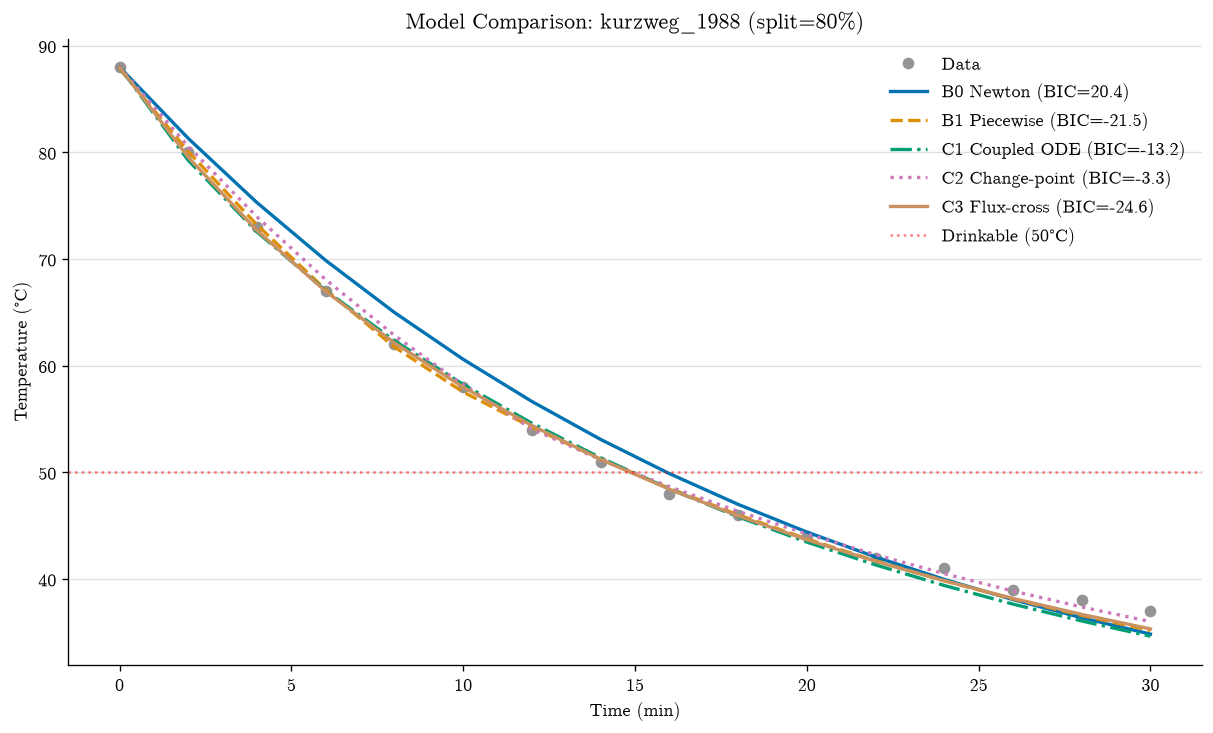

In [20]:
# Plot model predictions on the first dataset
entry = data[0]
results = process_dataset(entry, SPLIT_RATIO)
fit_data = {
    "t_min": entry["t_min"][:results["split_size_fit"]],
    "T_C": entry["T_C"][:results["split_size_fit"]],
    "T_env_C": entry["T_env_C"],
    "T0_C": entry["T0_C"],
}
hold_data = {
    "t_min": entry["t_min"][results["split_size_fit"]:],
    "T_C": entry["T_C"][results["split_size_fit"]:],
    "T_env_C": entry["T_env_C"],
}
Te = entry["T_env_C"]
T0 = entry["T0_C"]
t_all_s = np.array(entry["t_min"]) * 60.0
T_all = np.array(entry["T_C"])

# Generate predictions for each model
b0 = results["B0"]
b1 = results["B1"]
c1 = results["C1"]
c2 = results["C2"]
c3 = results["C3_best"]

pred_b0 = newton_model(t_all_s, b0["k"], T0, Te)
pred_b1 = piecewise_two_exponential(t_all_s, b1["k1"], b1["T0_1"], Te, b1["t_switch_s"], b1["k2"], b1["T0_2"], Te)

sol_c1 = solve_ivp(
    lambda tt, yy: coupled_TM_ode(tt, yy, Te, c1["params"][0], c1["params"][1], LATENT_HEAT_VAP_J_PER_KG, SPECIFIC_HEAT_WATER_J_PER_KG_K, c1["params"][2]),
    [0.0, t_all_s[-1]],
    [T0, 0.25],
    t_eval=t_all_s,
    max_step=5.0,
)
pred_c1 = sol_c1.y[0]

t_cp = c2["t_cp_s"]
k1, k2 = c2["k1"], c2["k2"]
mask1 = t_all_s <= t_cp
pred_c2 = np.empty_like(t_all_s)
if np.any(mask1):
    pred_c2[mask1] = Te + (T0 - Te) * np.exp(-k1 * t_all_s[mask1])
if np.any(~mask1):
    T_at_cp = Te + (T0 - Te) * np.exp(-k1 * t_cp)
    t_rel = t_all_s[~mask1] - t_cp
    pred_c2[~mask1] = Te + (T_at_cp - Te) * np.exp(-k2 * t_rel)

pred_c3 = flux_crossover_model(t_all_s, c3["k_conv"], T0, Te, c3["tau_min"], c3["beta"])

# Plot
plt.figure(figsize=(10, 6))
plt.plot(entry["t_min"], entry["T_C"], 'o', label='Data', color=COLOURS["baseline"], markersize=6)
plt.plot(entry["t_min"], pred_b0, '-', label=f'B0 Newton (BIC={results["B0"]["bic"]:.1f})', color=COLOURS["method"], linewidth=2)
plt.plot(entry["t_min"], pred_b1, '--', label=f'B1 Piecewise (BIC={results["B1"]["bic"]:.1f})', color=COLOURS["other_1"], linewidth=2)
plt.plot(entry["t_min"], pred_c1, '-.', label=f'C1 Coupled ODE (BIC={results["C1"]["bic"]:.1f})', color=COLOURS["other_2"], linewidth=2)
plt.plot(entry["t_min"], pred_c2, ':', label=f'C2 Change-point (BIC={results["C2"]["bic"]:.1f})', color=COLOURS["other_3"], linewidth=2)
plt.plot(entry["t_min"], pred_c3, '-', label=f'C3 Flux-cross (BIC={results["C3_best"]["bic"]:.1f})', color=COLOURS["other_4"], linewidth=2)
plt.axhline(DRINKABLE_TEMP_C, color='red', linestyle=':', alpha=0.5, label='Drinkable (50°C)')
plt.xlabel('Time (min)')
plt.ylabel('Temperature (°C)')
plt.title(f'Model Comparison: {entry["name"]} (split={SPLIT_RATIO:.0%})')
plt.legend()
plt.show()

### Results table

In [21]:
# Print a formatted comparison table
import pandas as pd

table_data = []
for entry in data:
    results = process_dataset(entry, SPLIT_RATIO)
    comp = results["comparison_row"]
    row = {
        "Dataset": entry["name"],
        "B0 BIC": f"{comp['bic_B0']:.1f}",
        "B1 BIC": f"{comp['bic_B1']:.1f}",
        "C1 BIC": f"{comp['bic_C1']:.1f}",
        "C2 BIC": f"{comp['bic_C2']:.1f}",
        "C3 BIC": f"{comp['bic_C3_best']:.1f}",
        "B0 RMSE": f"{comp['oos_rmse_B0']:.4f}",
        "B1 RMSE": f"{comp['oos_rmse_B1']:.4f}",
        "C1 RMSE": f"{comp['oos_rmse_C1']:.4f}",
        "C2 RMSE": f"{comp['oos_rmse_C2']:.4f}",
        "C3 RMSE": f"{comp['oos_rmse_C3_best']:.4f}",
        "B0 t_drink": f"{comp['t_drinkable_B0_min']:.2f}",
        "B1 t_drink": f"{comp['t_drinkable_B1_min']:.2f}",
        "C1 t_drink": f"{comp['t_drinkable_C1_min']:.2f}",
        "C2 t_drink": f"{comp['t_drinkable_C2_min']:.2f}",
        "C3 t_drink": f"{comp['t_drinkable_C3_best_min']:.2f}",
    }
    table_data.append(row)

df = pd.DataFrame(table_data)
print(df.to_string(index=False))

2026-11-24 18:46:37.621 -08:00 | INFO     | __main__:process_dataset:7 - Processing dataset: kurzweg_1988 (split=80%)


2026-11-24 18:46:37.622 -08:00 | INFO     | __main__:process_dataset:42 -   Fitting B0 (Newton) on kurzweg_1988


2026-11-24 18:46:37.623 -08:00 | INFO     | __main__:process_dataset:49 -   Fitting B1 (Piecewise) on kurzweg_1988


/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:32: OptimizeWarning: Covariance of the parameters could not be estimated
  p1, _ = curve_fit(
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:42: RuntimeWarning: overflow encountered in exp
  lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:42: RuntimeWarning: overflow encountered in multiply
  lambda tt, kk, T0_2: Te + (T0_2 - Te) * np.exp(-kk * tt),
/Volumes/aii-s20010/tmp/ipykernel_22379/2587863150.py:41: OptimizeWarning: Covariance of the parameters could not be estimated
  p2, _ = curve_fit(
2026-11-24 18:46:37.631 -08:00 | INFO     | __main__:process_dataset:56 -   Fitting C1 (Coupled ODE) on kurzweg_1988


2026-11-24 18:46:39.127 -08:00 | INFO     | __main__:process_dataset:63 -   Fitting C2 (Bayesian Change-point) on kurzweg_1988


2026-11-24 18:46:39.130 -08:00 | INFO     | __main__:process_dataset:70 -   Fitting C3 (Flux Crossover) sweep on kurzweg_1988


     Dataset B0 BIC B1 BIC C1 BIC C2 BIC C3 BIC B0 RMSE B1 RMSE C1 RMSE C2 RMSE C3 RMSE B0 t_drink B1 t_drink C1 t_drink C2 t_drink C3 t_drink
kurzweg_1988   20.4  -21.5  -13.2   -3.3  -24.6  1.5260  1.3639  1.8549  0.6427  1.2838      15.92      14.88      14.93      14.91      14.87
